# scATAC LEAF-1 embeddings versus coordinate binning across bin resolutions (Supplementary Figure 5)

Four scatter panels (10K, 30K, 100K, 300K bins). Each point is one cell type; the y-axis is the AUC of the LEAF-1 embedding classifier and the x-axis is the AUC of the coordinate-binning baseline at that resolution. The dashed diagonal marks equal performance.

Reads `../data/scatac_leaf1_vs_binning_auc.csv` and writes the figure to `../output/`. Source: `mil/mil_nested/scatac_visualization/supp_heatmap_binning.ipynb`.

In [1]:
from pathlib import Path
import sys

# Self-contained: works when run from this notebook's folder (nbconvert default),
# from the modality folder, or from the repo root.
nb_dir = Path.cwd()
if (nb_dir / "data").exists() and (nb_dir / "output").exists():
    MOD_DIR = nb_dir
elif (nb_dir.parent / "data").exists():
    MOD_DIR = nb_dir.parent
else:
    MOD_DIR = nb_dir
DATA = MOD_DIR / "data"
OUT = MOD_DIR / "output"
OUT.mkdir(exist_ok=True)

# Locate the shared style helper (src/leaf1figures) by walking up.
_p = nb_dir
while _p != _p.parent and not (_p / "src" / "leaf1figures").exists():
    _p = _p.parent
sys.path.insert(0, str(_p / "src"))

from leaf1figures.style import OKABE_ITO, savefig, set_paper_style
set_paper_style()
print("DATA:", DATA)
print("OUT :", OUT)

DATA: /home/hamedh/projects/fragmentomics/multi_modal_fragments/bert_window_embedding/draft/leaf-1-figures/scatac/data
OUT : /home/hamedh/projects/fragmentomics/multi_modal_fragments/bert_window_embedding/draft/leaf-1-figures/scatac/output


saved: /home/hamedh/projects/fragmentomics/multi_modal_fragments/bert_window_embedding/draft/leaf-1-figures/scatac/output/scatac_embedding_vs_binning_resolution.pdf
saved: /home/hamedh/projects/fragmentomics/multi_modal_fragments/bert_window_embedding/draft/leaf-1-figures/scatac/output/scatac_embedding_vs_binning_resolution.png
saved: /home/hamedh/projects/fragmentomics/multi_modal_fragments/bert_window_embedding/draft/leaf-1-figures/scatac/output/scatac_embedding_vs_binning_resolution.svg
saved: /home/hamedh/projects/fragmentomics/multi_modal_fragments/bert_window_embedding/draft/leaf-1-figures/scatac/output/scatac_embedding_vs_binning_resolution.tsv


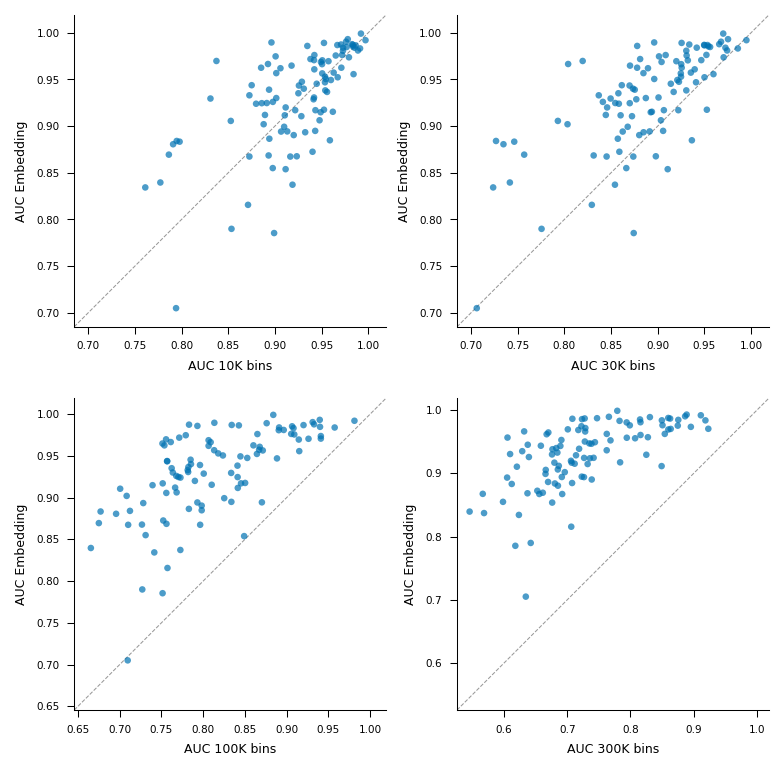

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
# Exact-source rcParams for this panel family.
plt.rcParams.update({
    'font.family': 'sans-serif',
    'font.sans-serif': ['DejaVu Sans', 'Liberation Sans', 'Arial', 'Helvetica'],
    'font.size': 6,
    'axes.titlesize': 7,
    'axes.labelsize': 6,
    'xtick.labelsize': 5,
    'ytick.labelsize': 5,
    'legend.fontsize': 5,
    'axes.linewidth': 0.5,
    'xtick.major.width': 0.5,
    'ytick.major.width': 0.5,
    'figure.dpi': 150,
    'savefig.dpi': 600,
    'pdf.fonttype': 42,
})

df = pd.read_csv(DATA / 'scatac_leaf1_vs_binning_auc.csv')

# (column, panel title) for the four bin resolutions
PANELS = [
    ('bin_10k_auc', 'AUC 10K bins'),
    ('bin_30k_auc', 'AUC 30K bins'),
    ('bin_100k_auc', 'AUC 100K bins'),
    ('bin_300k_auc', 'AUC 300K bins'),
]

y = df['leaf1_auc'].values  # Embedding AUC (same on every panel)

fig, axes = plt.subplots(2, 2, figsize=(5.2, 5.2))
for ax, (col, xlabel) in zip(axes.ravel(), PANELS):
    x = df[col].values
    ax.scatter(x, y, c=OKABE_ITO['blue'], s=10, alpha=0.7,
               edgecolors='none', zorder=3, rasterized=True)
    # Per-panel auto-scaled square limits with a small margin.
    lo = min(x.min(), y.min()) - 0.02
    hi = max(x.max(), y.max()) + 0.02
    ax.plot([lo, hi], [lo, hi], ls='--', color='0.6', lw=0.5, zorder=1)
    ax.set_xlim(lo, hi)
    ax.set_ylim(lo, hi)
    ax.set_aspect('equal')
    ax.set_xlabel(xlabel, fontsize=6)
    ax.set_ylabel('AUC Embedding', fontsize=6)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)

plt.tight_layout()
savefig(fig, OUT, 'scatac_embedding_vs_binning_resolution', data=(df))